Doanload Dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

BASE_DIR = "/content/drive/MyDrive/BrainTumor_Morphology"
DATA_DIR = os.path.join(BASE_DIR, "data")

os.makedirs(DATA_DIR, exist_ok=True)

print("Base dir:", BASE_DIR)
print("Data dir:", DATA_DIR)

Base dir: /content/drive/MyDrive/BrainTumor_Morphology
Data dir: /content/drive/MyDrive/BrainTumor_Morphology/data


In [ ]:
# import kagglehub
# import shutil
# import os

# tmp_path = kagglehub.dataset_download(
#     "mateuszbuda/lgg-mri-segmentation"
# )

# print("Temporary download path:", tmp_path)

# dst_path = os.path.join(DATA_DIR, "LGG")
# if not os.path.exists(dst_path):
#     # Use shutil.copytree instead of shutil.move because tmp_path is a read-only file system.
#     # shutil.move attempts to delete the source, which is not allowed.
#     shutil.copytree(tmp_path, dst_path)

# print("Dataset moved to:", dst_path)

In [ ]:
import os

DATASET_DIR = "/content/drive/MyDrive/BrainTumor_Morphology/data/LGG"

os.listdir(DATASET_DIR)

['lgg-mri-segmentation', 'kaggle_3m']

In [ ]:
for root, dirs, files in os.walk(DATASET_DIR):
    level = root.replace(DATASET_DIR, "").count(os.sep)
    if level > 2:
        continue
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")
    for f in files[:5]:
        print(f"{indent}  {f}")

LGG/
  lgg-mri-segmentation/
    kaggle_3m/
      README.md
      data.csv
  kaggle_3m/
    README.md
    data.csv
    TCGA_CS_4944_20010208/
      TCGA_CS_4944_20010208_18_mask.tif
      TCGA_CS_4944_20010208_13_mask.tif
      TCGA_CS_4944_20010208_16_mask.tif
      TCGA_CS_4944_20010208_4.tif
      TCGA_CS_4944_20010208_9_mask.tif
    TCGA_DU_5852_19950709/
      TCGA_DU_5852_19950709_6_mask.tif
      TCGA_DU_5852_19950709_4.tif
      TCGA_DU_5852_19950709_32_mask.tif
      TCGA_DU_5852_19950709_33.tif
      TCGA_DU_5852_19950709_16_mask.tif
    TCGA_CS_4941_19960909/
      TCGA_CS_4941_19960909_13_mask.tif
      TCGA_CS_4941_19960909_15_mask.tif
      TCGA_CS_4941_19960909_22.tif
      TCGA_CS_4941_19960909_9_mask.tif
      TCGA_CS_4941_19960909_19_mask.tif
    TCGA_CS_6667_20011105/
      TCGA_CS_6667_20011105_7_mask.tif
      TCGA_CS_6667_20011105_4_mask.tif
      TCGA_CS_6667_20011105_3_mask.tif
      TCGA_CS_6667_20011105_8_mask.tif
      TCGA_CS_6667_20011105_6.tif
    TCGA_DU_

Load an image and sanity check

In [ ]:
import os

DATASET_DIR = "/content/drive/MyDrive/BrainTumor_Morphology/data/LGG/kaggle_3m"

patients = sorted([
    d for d in os.listdir(DATASET_DIR)
    if os.path.isdir(os.path.join(DATASET_DIR, d))
])

print("Number of patients:", len(patients))
print("Sample patients:", patients[:5])

Number of patients: 110
Sample patients: ['TCGA_CS_4941_19960909', 'TCGA_CS_4942_19970222', 'TCGA_CS_4943_20000902', 'TCGA_CS_4944_20010208', 'TCGA_CS_5393_19990606']


In [ ]:
import glob

patient_dir = os.path.join(DATASET_DIR, patients[0])
all_files = os.listdir(patient_dir)

image_files = [f for f in all_files if f.endswith(".tif") and "_mask" not in f]
mask_files  = [f for f in all_files if f.endswith("_mask.tif")]

print("Images:", image_files[:5])
print("Masks:", mask_files[:5])

# انتخاب اولین pair معتبر
img_name = image_files[0]
mask_name = img_name.replace(".tif", "_mask.tif")

print("Selected image:", img_name)
print("Selected mask:", mask_name)

Images: ['TCGA_CS_4941_19960909_22.tif', 'TCGA_CS_4941_19960909_9.tif', 'TCGA_CS_4941_19960909_10.tif', 'TCGA_CS_4941_19960909_19.tif', 'TCGA_CS_4941_19960909_2.tif']
Masks: ['TCGA_CS_4941_19960909_13_mask.tif', 'TCGA_CS_4941_19960909_15_mask.tif', 'TCGA_CS_4941_19960909_9_mask.tif', 'TCGA_CS_4941_19960909_19_mask.tif', 'TCGA_CS_4941_19960909_12_mask.tif']
Selected image: TCGA_CS_4941_19960909_22.tif
Selected mask: TCGA_CS_4941_19960909_22_mask.tif


In [ ]:
import cv2
import matplotlib.pyplot as plt

img_path  = os.path.join(patient_dir, img_name)
mask_path = os.path.join(patient_dir, mask_name)

img  = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

print("Image shape:", img.shape, "dtype:", img.dtype)
print("Mask shape :", mask.shape, "dtype:", mask.dtype)
print("Mask unique values:", set(mask.flatten()))

Image shape: (256, 256) dtype: uint8
Mask shape : (256, 256) dtype: uint8
Mask unique values: {np.uint8(0)}


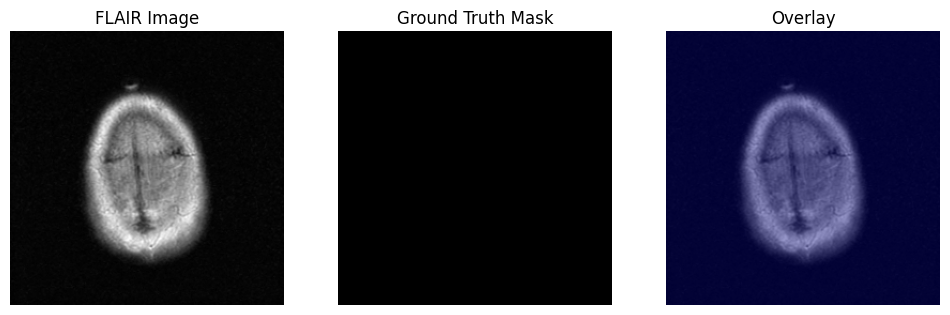

In [ ]:
plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(img, cmap="gray")
plt.title("FLAIR Image")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(mask, cmap="gray")
plt.title("Ground Truth Mask")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(img, cmap="gray")
plt.imshow(mask, cmap="jet", alpha=0.4)
plt.title("Overlay")
plt.axis("off")

plt.show()

brain with tumor

In [ ]:
import cv2
import os
import numpy as np

valid_pair = None

for img_name in image_files:
    mask_name = img_name.replace(".tif", "_mask.tif")
    if mask_name in mask_files:
        mask_path = os.path.join(patient_dir, mask_name)
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        if mask is not None and np.any(mask > 0):
            valid_pair = (img_name, mask_name)
            break

print("Valid pair found:", valid_pair)


Valid pair found: ('TCGA_CS_4941_19960909_12.tif', 'TCGA_CS_4941_19960909_12_mask.tif')


Mask unique values: {np.uint8(0), np.uint8(255)}


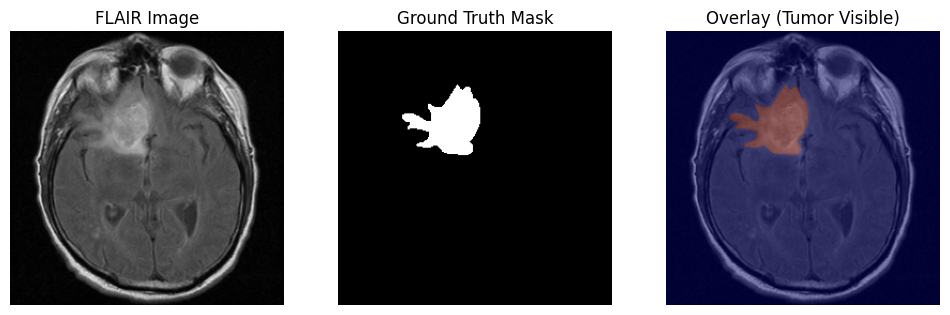

In [ ]:
img_name, mask_name = valid_pair

img_path  = os.path.join(patient_dir, img_name)
mask_path = os.path.join(patient_dir, mask_name)

img  = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

print("Mask unique values:", set(mask.flatten()))

import matplotlib.pyplot as plt

plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(img, cmap="gray")
plt.title("FLAIR Image")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(mask, cmap="gray")
plt.title("Ground Truth Mask")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(img, cmap="gray")
plt.imshow(mask, cmap="jet", alpha=0.4)
plt.title("Overlay (Tumor Visible)")
plt.axis("off")

plt.show()

Image preprocessing

In [ ]:
img_raw  = img.copy()
mask_gt  = mask.copy()

Bright FLAIR outliers

Preserves local tumor contrast

In [ ]:
import numpy as np

def percentile_normalize(img, p_low=1, p_high=99):
    lo = np.percentile(img, p_low)
    hi = np.percentile(img, p_high)
    img_clipped = np.clip(img, lo, hi)
    img_norm = (img_clipped - lo) / (hi - lo + 1e-8)
    return (img_norm * 255).astype(np.uint8)

img_norm = percentile_normalize(img_raw)

noise removal
Median filter

In [ ]:
import cv2

img_denoised = cv2.medianBlur(img_norm, 3)

Extraction of primary tumor candidates

Adaptive Threshold (Otsu on ROI)

In [ ]:
_, img_thresh = cv2.threshold(
    img_denoised, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

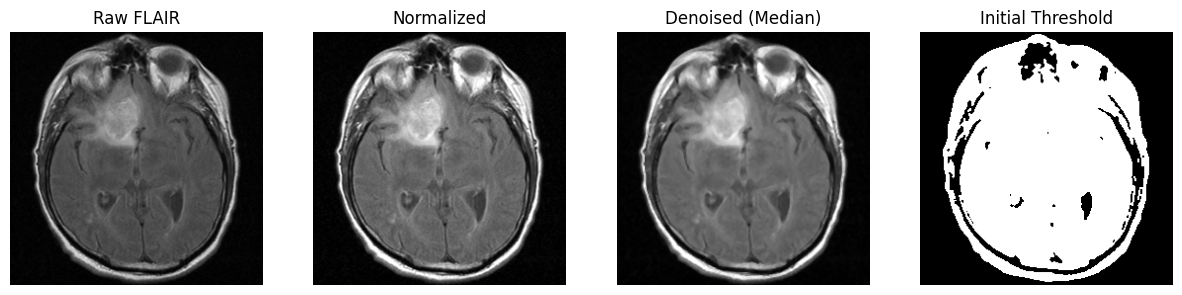

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15,4))

plt.subplot(1,4,1)
plt.imshow(img_raw, cmap='gray')
plt.title("Raw FLAIR")
plt.axis('off')

plt.subplot(1,4,2)
plt.imshow(img_norm, cmap='gray')
plt.title("Normalized")
plt.axis('off')

plt.subplot(1,4,3)
plt.imshow(img_denoised, cmap='gray')
plt.title("Denoised (Median)")
plt.axis('off')

plt.subplot(1,4,4)
plt.imshow(img_thresh, cmap='gray')
plt.title("Initial Threshold")
plt.axis('off')

plt.show()

To extract the boundary with top hat

In [ ]:
from skimage.morphology import white_tophat, disk

tophat = white_tophat(img_denoised, disk(15))
_, boundary_segment = cv2.threshold(tophat, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
boundary_removed = cv2.bitwise_and(img_thresh, cv2.bitwise_not(boundary_segment))

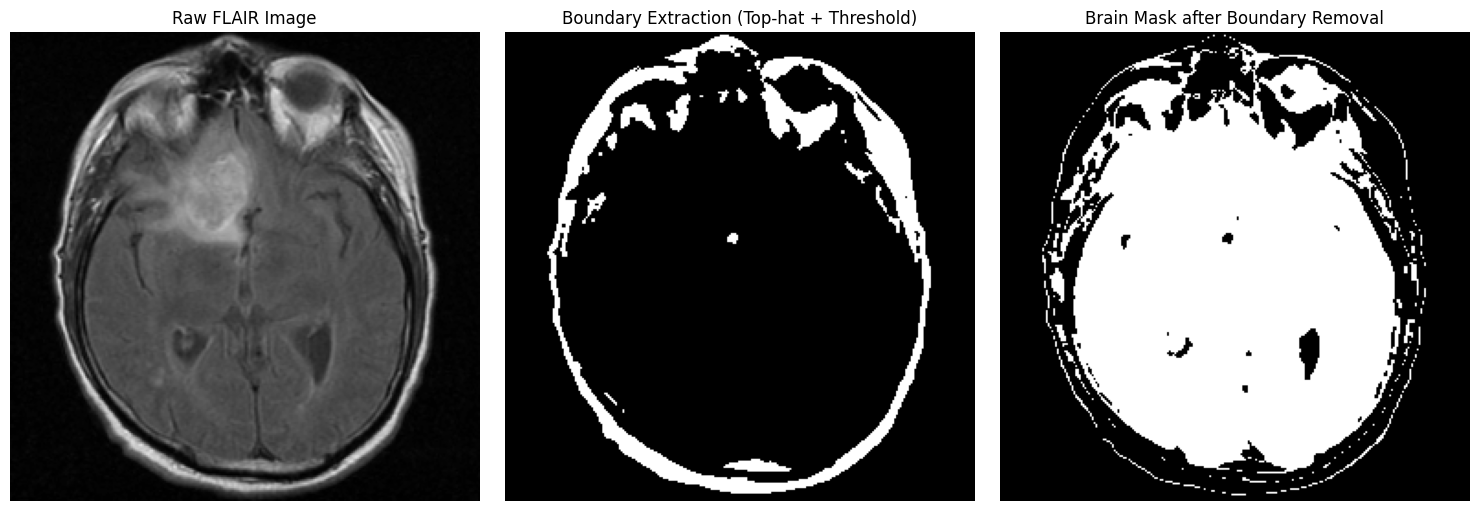

In [ ]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img_raw, cmap='gray')
plt.title("Raw FLAIR Image")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(boundary_segment, cmap='gray')
plt.title("Boundary Extraction (Top-hat + Threshold)")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(boundary_removed, cmap='gray')
plt.title("Brain Mask after Boundary Removal")
plt.axis('off')

plt.tight_layout()
plt.show()

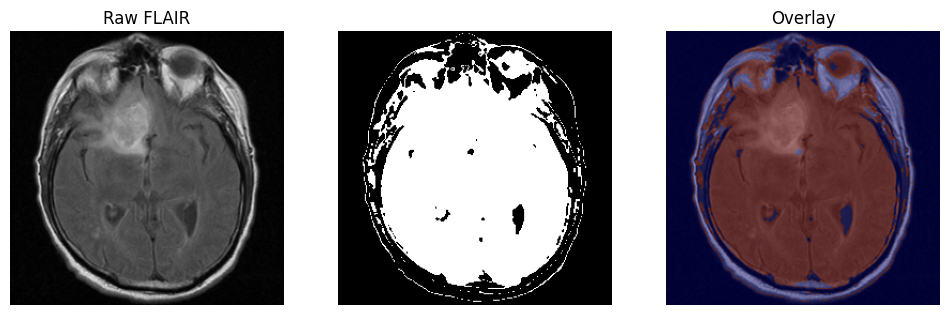

In [ ]:
plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(img_raw, cmap='gray')
plt.title("Raw FLAIR")
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(boundary_removed, cmap='gray')
plt.title("")
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(img_raw, cmap='gray')
plt.imshow(boundary_removed, cmap='jet', alpha=0.4)
plt.title("Overlay")
plt.axis('off')

plt.show()

opening

In [ ]:
from skimage.morphology import erosion, dilation, disk

# erosion
eroded_mask = erosion(boundary_removed, disk(9))

# dilation
dilation_mask = dilation(eroded_mask, disk(11))

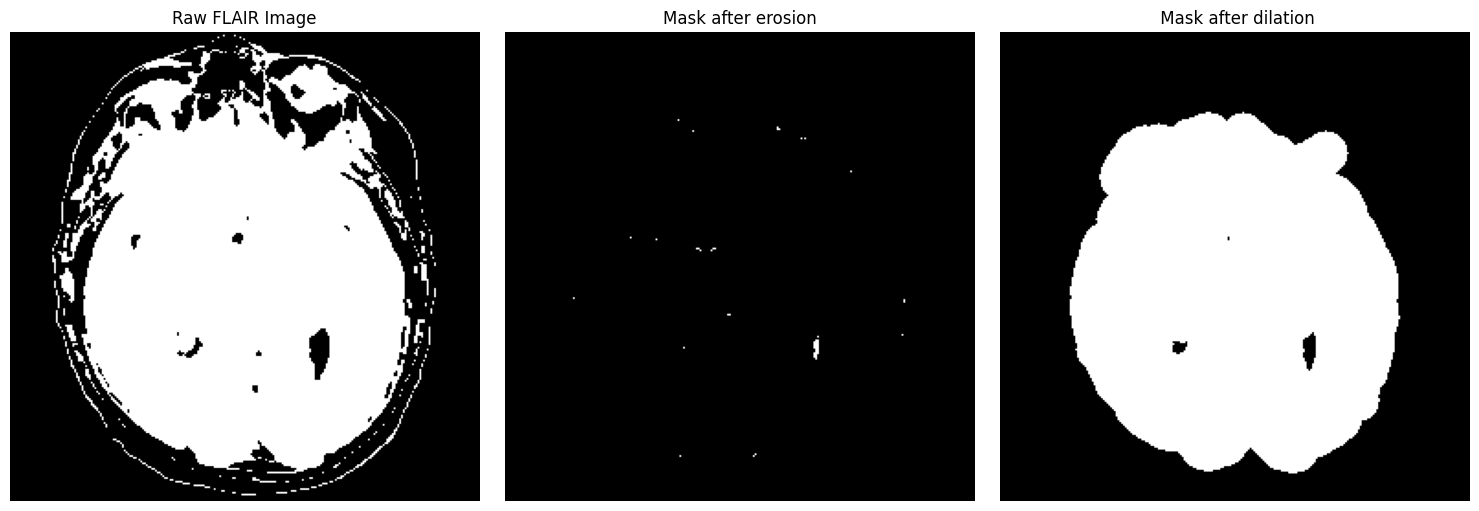

In [ ]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(boundary_removed, cmap='gray')
plt.title("Raw FLAIR Image")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(eroded_mask, cmap='gray')
plt.title("Mask after erosion")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(dilation_mask, cmap='gray')
plt.title(" Mask after dilation")
plt.axis('off')

plt.tight_layout()
plt.show()


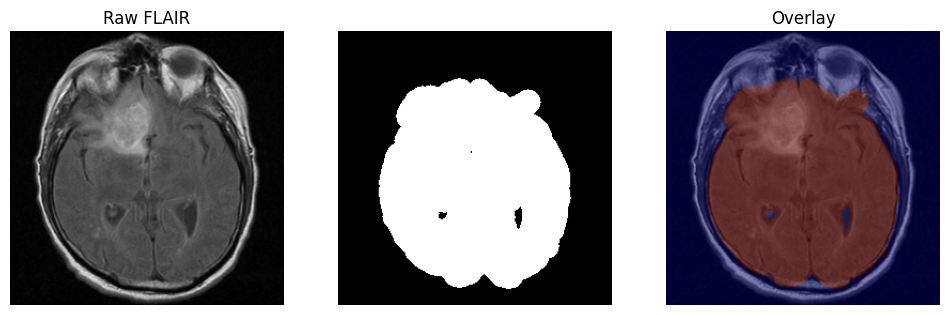

In [ ]:
plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(img_raw, cmap='gray')
plt.title("Raw FLAIR")
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(dilation_mask, cmap='gray')
plt.title("")
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(img_raw, cmap='gray')
plt.imshow(dilation_mask, cmap='jet', alpha=0.4)
plt.title("Overlay")
plt.axis('off')

plt.show()

top hat for extraxt tumor

In [ ]:
img_core = cv2.bitwise_and(img_denoised, dilation_mask)

tophat_core = white_tophat(img_core, disk(55))

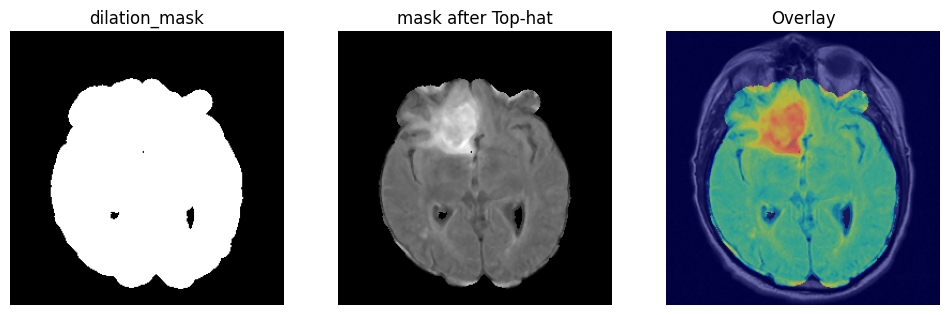

In [ ]:
plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(dilation_mask, cmap='gray')
plt.title("dilation_mask")
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(tophat_core, cmap='gray')
plt.title("mask after Top-hat")
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(img_raw, cmap='gray')
plt.imshow(tophat_core, cmap='jet', alpha=0.5)
plt.title("Overlay")
plt.axis('off')

plt.show()

Threshold

In [ ]:
# Threshold
_, tumor_segment = cv2.threshold(tophat_core, 125, 255, cv2.THRESH_BINARY)


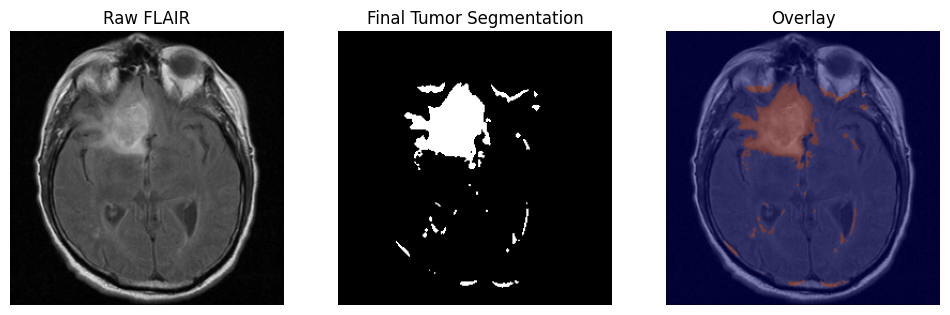

In [ ]:
plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(img_raw, cmap='gray')
plt.title("Raw FLAIR")
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(tumor_segment, cmap='gray')
plt.title("Final Tumor Segmentation")
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(img_raw, cmap='gray')
plt.imshow(tumor_segment, cmap='jet', alpha=0.4)
plt.title("Overlay")
plt.axis('off')

plt.show()


opening

In [ ]:
eroded_tumor = erosion(tumor_segment, disk(3))

final_tumor = dilation(eroded_tumor, disk(3))


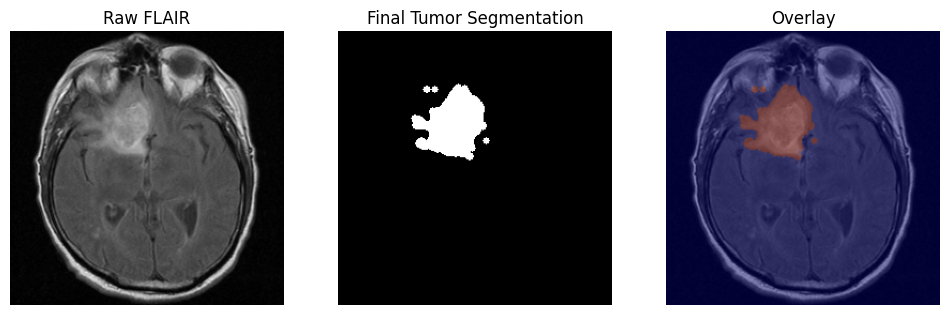

In [ ]:
plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(img_raw, cmap='gray')
plt.title("Raw FLAIR")
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(final_tumor, cmap='gray')
plt.title("Final Tumor Segmentation")
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(img_raw, cmap='gray')
plt.imshow(final_tumor, cmap='jet', alpha=0.4)
plt.title("Overlay")
plt.axis('off')

plt.show()


connectedComponents

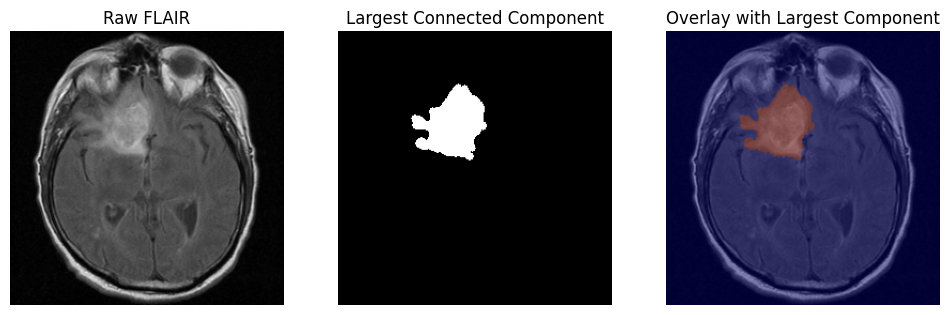

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(final_tumor, connectivity=8)

areas = stats[1:, cv2.CC_STAT_AREA]

largest_component_mask = np.zeros_like(final_tumor)

if areas.size > 0:
    largest_label_index = np.argmax(areas) + 1

    largest_component_mask[labels == largest_label_index] = 255


plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(img_raw, cmap='gray')
plt.title("Raw FLAIR")
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(largest_component_mask, cmap='gray')
plt.title("Largest Connected Component")
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(img_raw, cmap='gray')
plt.imshow(largest_component_mask, cmap='jet', alpha=0.4)
plt.title("Overlay with Largest Component")
plt.axis('off')

plt.show()